# Plot Consumption

Plot the four-home sample for January-August 2013.

Open this notebook in `notebooks/M5/`. Run the cells in order. Saving again replaces this notebook's output files.


## Shared folder setup

In [2]:
from pathlib import Path
PROJECT_ROOT = Path("../..").resolve()
PROJECT_ROOT

WindowsPath('C:/Projects/Data mining project/household-energy-prediction')

## Read the half-hour sample

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
raw_path = PROJECT_ROOT / "data/pilot/half_hour_sample.csv"
raw = pd.read_csv(raw_path, na_values=["Null", "null"])
raw.head()

,LCLid,tstp,energy(kWh/hh)
0,MAC000414,2013-01-01 00:00:00.0000000,0.130
1,MAC000414,2013-01-01 00:30:00.0000000,0.125
2,MAC000414,2013-01-01 01:00:00.0000000,0.148
3,MAC000414,2013-01-01 01:30:00.0000000,0.095
4,MAC000414,2013-01-01 02:00:00.0000000,0.098


## Parse the values and raw times

In [4]:
raw["tstp"] = pd.to_datetime(raw["tstp"], utc=True)
raw["energy"] = pd.to_numeric(raw["energy(kWh/hh)"])
raw["interval_start"] = raw["tstp"] - pd.Timedelta(minutes=30)
raw.head()

,LCLid,tstp,energy(kWh/hh),energy,interval_start
0,MAC000414,2013-01-01 00:00:00+00:00,0.130,0.130,2012-12-31 23:30:00+00:00
1,MAC000414,2013-01-01 00:30:00+00:00,0.125,0.125,2013-01-01 00:00:00+00:00
2,MAC000414,2013-01-01 01:00:00+00:00,0.148,0.148,2013-01-01 00:30:00+00:00
3,MAC000414,2013-01-01 01:30:00+00:00,0.095,0.095,2013-01-01 01:00:00+00:00
4,MAC000414,2013-01-01 02:00:00+00:00,0.098,0.098,2013-01-01 01:30:00+00:00


## Keep only the training period

In [5]:
start = pd.Timestamp("2013-01-01", tz="UTC")
end = pd.Timestamp("2013-09-01", tz="UTC")
train = raw[(raw["interval_start"] >= start) & (raw["interval_start"] < end)].copy()
train.head()

,LCLid,tstp,energy(kWh/hh),energy,interval_start
1,MAC000414,2013-01-01 00:30:00+00:00,0.125,0.125,2013-01-01 00:00:00+00:00
2,MAC000414,2013-01-01 01:00:00+00:00,0.148,0.148,2013-01-01 00:30:00+00:00
3,MAC000414,2013-01-01 01:30:00+00:00,0.095,0.095,2013-01-01 01:00:00+00:00
4,MAC000414,2013-01-01 02:00:00+00:00,0.098,0.098,2013-01-01 01:30:00+00:00
5,MAC000414,2013-01-01 02:30:00+00:00,0.025,0.025,2013-01-01 02:00:00+00:00


## Use the four development homes

In [6]:
homes = ["MAC000414", "MAC000675", "MAC001312", "MAC005456"]
sample_home = "MAC000414"
train = train[train["LCLid"].isin(homes)]
train.groupby("LCLid").size()

LCLid
MAC000414    11517
MAC000675    11664
MAC001312    11664
MAC005456    11518
dtype: int64

## List all expected half-hours

In [7]:
times = pd.date_range(start, end, freq="30min", inclusive="left")
grid = pd.MultiIndex.from_product([homes, times], names=["LCLid", "interval_start"])
len(times), len(grid)

(11664, 46656)

## Place observed energy on the grid

In [8]:
observed = train.set_index(["LCLid", "interval_start"])["energy"]
energy = observed.reindex(grid)
energy.head()

LCLid      interval_start           
MAC000414  2013-01-01 00:00:00+00:00    0.125
           2013-01-01 00:30:00+00:00    0.148
           2013-01-01 01:00:00+00:00    0.095
           2013-01-01 01:30:00+00:00    0.098
           2013-01-01 02:00:00+00:00    0.025
Name: energy, dtype: float64

## Distinguish absent rows from missing measurements

In [9]:
present = pd.Series(grid.isin(observed.index), index=grid)
missing_rows = ~present
missing_measurements = present & energy.isna()
missing_rows.groupby(level="LCLid").sum()

LCLid
MAC000414    147
MAC000675      0
MAC001312      0
MAC005456    146
dtype: int64

## Build a simple missing readings table

In [10]:
coverage = pd.DataFrame(index=pd.Index(homes, name="LCLid"))
coverage["expected_intervals"] = len(times)
coverage["absent_intervals"] = missing_rows.groupby(level="LCLid").sum()
coverage["missing_measurements"] = missing_measurements.groupby(level="LCLid").sum()
coverage["available_intervals"] = energy.notna().groupby(level="LCLid").sum()
coverage["total_missing"] = coverage["absent_intervals"] + coverage["missing_measurements"]
coverage

,expected_intervals,absent_intervals,missing_measurements,available_intervals,total_missing
LCLid,,,,,
MAC000414,11664,147,0,11517,147
MAC000675,11664,0,0,11664,0
MAC001312,11664,0,0,11664,0
MAC005456,11664,146,0,11518,146


## Read the example home's curve values

In [11]:
curve = energy.loc[sample_home]
curve.head()

interval_start
2013-01-01 00:00:00+00:00    0.125
2013-01-01 00:30:00+00:00    0.148
2013-01-01 01:00:00+00:00    0.095
2013-01-01 01:30:00+00:00    0.098
2013-01-01 02:00:00+00:00    0.025
Freq: 30min, Name: energy, dtype: float64

## Count its available and missing intervals

In [12]:
curve_available = curve.notna().sum()
curve_missing = curve.isna().sum()
curve_available, curve_missing

(np.int64(11517), np.int64(147))

## Chart 1: consumption over time

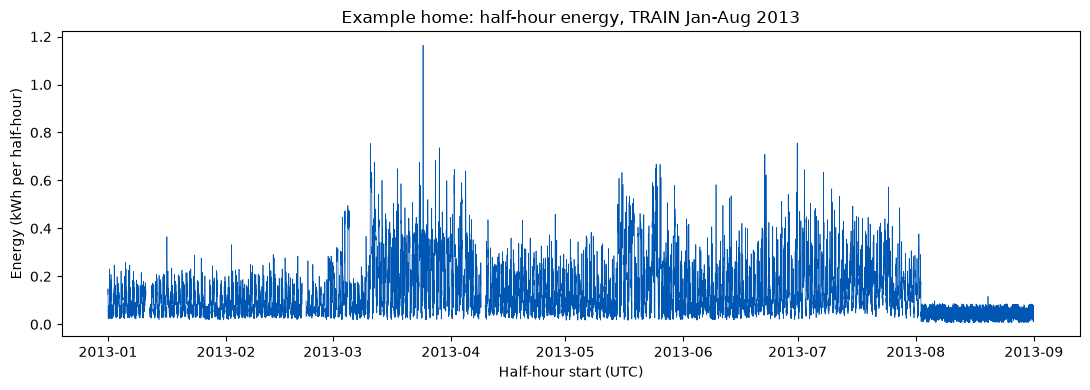

In [13]:
curve_fig, curve_ax = plt.subplots(figsize=(11, 4))
curve_ax.plot(curve.index, curve, linewidth=0.5, color="#0056b3")
curve_ax.set_title("Example home: half-hour energy, TRAIN Jan-Aug 2013")
curve_ax.set_xlabel("Half-hour start (UTC)")
curve_ax.set_ylabel("Energy (kWh per half-hour)")
curve_fig.tight_layout()
plt.show()

## Keep measured readings for the histogram

In [14]:
valid_kwh = energy.dropna()
total_missing = energy.isna().sum()
len(valid_kwh), total_missing

(46363, np.int64(293))

## Chart 2: distribution of measured energy

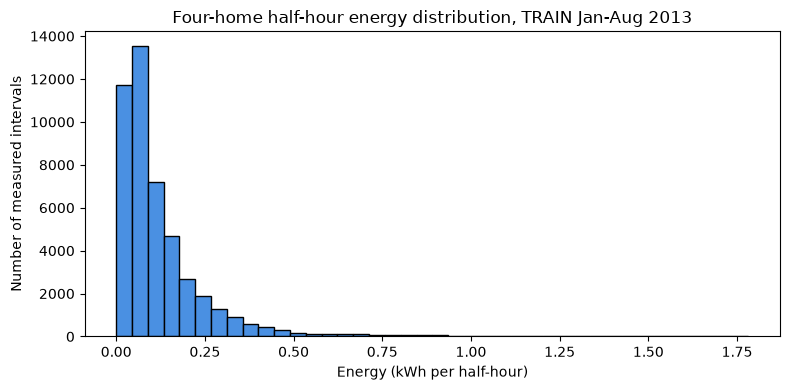

In [15]:
distribution_fig, distribution_ax = plt.subplots(figsize=(8, 4))
distribution_ax.hist(valid_kwh, bins=40, edgecolor="black", color="#4A90E2")
distribution_ax.set_title("Four-home half-hour energy distribution, TRAIN Jan-Aug 2013")
distribution_ax.set_xlabel("Energy (kWh per half-hour)")
distribution_ax.set_ylabel("Number of measured intervals")
distribution_fig.tight_layout()
plt.show()

## Choose the output folder

In [16]:
output_dir = PROJECT_ROOT / 'data/processed'
output_dir.mkdir(parents=True, exist_ok=True)
output_dir

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/data/processed')

## Save the time curve

In [17]:
curve_path = PROJECT_ROOT / "figures" / "household_consumption_sample.png"
curve_fig.savefig(curve_path, dpi=150)
curve_path

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/figures/household_consumption_sample.png')

## Save the distribution

In [18]:
distribution_path = PROJECT_ROOT / "figures" / "consumption_distribution_sample.png"
distribution_fig.savefig(distribution_path, dpi=150)
distribution_path

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/figures/consumption_distribution_sample.png')

## Save the missing readings counts

In [19]:
coverage_path = output_dir / "half_hour_coverage_sample.csv"
coverage.to_csv(coverage_path, index_label="LCLid")
coverage_path

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/data/processed/half_hour_coverage_sample.csv')

## Prepare the time-curve caption

In [20]:
curve_caption = (
    f"Home {sample_home}, Jan-Aug 2013. Energy is kWh per half-hour. "
    f"Available: {curve_available}; missing: {curve_missing}. Gaps show missing readings."
)
curve_caption

'Home MAC000414, Jan-Aug 2013. Energy is kWh per half-hour. Available: 11517; missing: 147. Gaps show missing readings.'

## Prepare the distribution caption

In [21]:
distribution_caption = (
    f"Four homes, Jan-Aug 2013. {len(valid_kwh)} half-hour readings in kWh. "
    f"Missing readings excluded: {total_missing}. Measured zeros are included."
)
distribution_caption

'Four homes, Jan-Aug 2013. 46363 half-hour readings in kWh. Missing readings excluded: 293. Measured zeros are included.'

## Save the captions

In [22]:
notes_path = PROJECT_ROOT / "figures" / "consumption_chart_notes_sample.md"
notes = "# M5 sample chart notes\n\n## Time curve\n\n" + curve_caption + "\n\n## Distribution\n\n" + distribution_caption + "\n"
notes_path.write_text(notes, encoding="utf-8")
notes_path

WindowsPath('C:/Projects/Data mining project/household-energy-prediction/figures/consumption_chart_notes_sample.md')